# Phase 1 — RNN + Transformer fusion language model

Third architecture for Phase 1. Everything upstream of the model is reused, so results stay comparable with the decoder-only and encoder-decoder runs:

- **Tokenizer:** `legal_bpe_v3.pkl` (byte-level BPE, 40k vocab)
- **Data:** `train_v3.bin` / `val_v3.bin` (uint16 token ids, four sources mixed 25% each)
- **Task:** next-token prediction, `model(idx) -> logits`, validated on the same 40 windows as the decoder-only run

Cells 1–5 are copied unchanged from the previous `models.ipynb` (outputs cleared).

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("CS781_WRITE")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/legal_bpe_v3.pkl
/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/val_v3.bin
/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/train_v3.bin


In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [4]:
import re
import pickle
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import time

from datasets import load_dataset


class LegalBPETokenizer:

    def __init__(self, model_path):

        with open(model_path, "rb") as f:
            model = pickle.load(f)

        self.vocab_size = model["vocab_size"]
        self.merges = model["merges"]                     # [((a, b), new_id), ...]
        self.lowercase = model.get("lowercase", False)
        self.special_tokens = model.get("special_tokens", [])
        self.pattern = re.compile(model["pattern"])

        # pair -> rank (lower rank = learned earlier = merged first)
        self.merge_rank = {
            tuple(pair): rank
            for rank, (pair, _) in enumerate(self.merges)
        }

        # id -> bytes table (O(1) decode)
        self.token_bytes = {i: bytes([i]) for i in range(256)}
        for (l, r), new_id in self.merges:
            self.token_bytes[new_id] = self.token_bytes[l] + self.token_bytes[r]

        base = 256 + len(self.merges)
        self.special_to_id = {t: base + i for i, t in enumerate(self.special_tokens)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.eos_id = self.special_to_id.get("<|endoftext|>")

        self._special_re = (
            re.compile("(" + "|".join(re.escape(t) for t in self.special_tokens) + ")")
            if self.special_tokens else None
        )
        self._cache = {}

    def _encode_piece(self, piece_bytes):

        cached = self._cache.get(piece_bytes)
        if cached is not None:
            return cached

        ids = list(piece_bytes)

        while len(ids) > 1:
            best, best_rank = None, None
            for p in zip(ids, ids[1:]):
                r = self.merge_rank.get(p)
                if r is not None and (best_rank is None or r < best_rank):
                    best, best_rank = p, r
            if best is None:
                break

            new_id = 256 + best_rank
            out, i = [], 0
            while i < len(ids):
                if i < len(ids) - 1 and ids[i] == best[0] and ids[i + 1] == best[1]:
                    out.append(new_id)
                    i += 2
                else:
                    out.append(ids[i])
                    i += 1
            ids = out

        if len(self._cache) < 500_000:
            self._cache[piece_bytes] = ids
        return ids

    def _encode_ordinary(self, text):

        if self.lowercase:
            text = text.lower()

        out = []
        for piece in self.pattern.findall(text):
            out.extend(self._encode_piece(piece.encode("utf-8")))
        return out

    def encode(self, text, add_eos=False):

        if self._special_re is not None:
            ids = []
            for part in self._special_re.split(text):
                if part in self.special_to_id:
                    ids.append(self.special_to_id[part])
                elif part:
                    ids.extend(self._encode_ordinary(part))
        else:
            ids = self._encode_ordinary(text)

        if add_eos:
            ids.append(self.eos_id)

        return ids

    def decode(self, ids):

        chunks = []
        for token_id in ids:
            if token_id in self.id_to_special:
                chunks.append(self.id_to_special[token_id].encode("utf-8"))
            else:
                chunks.append(self.token_bytes[token_id])

        return b"".join(chunks).decode("utf-8", errors="replace")


TOKENIZER_PATH = "/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/legal_bpe_v3.pkl"   # <-- change this

tokenizer = LegalBPETokenizer(TOKENIZER_PATH)

print("Vocabulary size:", tokenizer.vocab_size)
print([tokenizer.decode([i]) for i in tokenizer.encode("dog ate cat")])

Vocabulary size: 40000
['dog', ' ate', ' cat']


In [5]:
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

supreme_court_dataset = load_dataset(
    "json",
    data_files={
        "train": f"hf://datasets/{HF_DATASET_REPO}/Phase_1_Pretraining/Train/train_supreme_court.json"
    },
    split="train",
    streaming=True
)

print("SC dataset loaded.")

SC dataset loaded.


## Model code

`model_arch_fusion.py` is the one piece this notebook does **not** write for you: the course rules ask for the model architecture to be your own implementation. The next cell creates the file with the config and the interface the rest of the notebook depends on — fill in the `TODO`s.

**Contract** (every later cell relies only on this):
- `FusionLM(cfg)` is an `nn.Module` exposing `.cfg.max_seq_len`
- `forward(idx)`: `LongTensor (B, T)` → logits `(B, T, vocab_size)` for any `1 <= T <= max_seq_len`
- strictly causal: `logits[:, t]` may depend only on `idx[:, :t+1]` (the sanity-check cell tests this)
- 50M–300M parameters (the decoder-only and encoder-decoder baselines are both ≈111M, so aim near that for a fair comparison)

**Design questions to settle before coding**
- How do the recurrent path and the attention path combine — stacked one after the other, run in parallel and merged, or interleaved layer by layer — and what does the merge look like (sum, concat + projection, learned gate)?
- Which path supplies position information, and does the attention path still need explicit positions?
- Which recurrent cell, and is it unidirectional? (It must be, for causality.)
- Training stability: recurrent paths under fp16 autocast; gradient clipping is already in the training loop.

In [14]:
%%writefile model_arch_fusion.py

"""RNN + Transformer fusion causal language model.

Block:  x -> x + Mix(norm1(x)) -> x + MLP(norm2(x))
Mix  =  causal self-attention (RoPE) in PARALLEL with a unidirectional GRU on the
        same normed input, merged by a learned gate: (1-g)*attn + g*rnn.
The GRU branch is present in every `rnn_every`-th block. Output head is tied.
"""

import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class FusionConfig:

    vocab_size: int

    # defaults mirror the decoder-only run so the two are easy to compare
    d_model: int = 768
    n_layers: int = 12
    n_heads: int = 12
    d_ff: int = 2816

    max_seq_len: int = 1024

    dropout: float = 0.0          # < 1 epoch of data: dropout mostly slows learning

    # ---- fusion-specific fields ----
    rnn_hidden: int = 512         # GRU hidden size (projected back to d_model)
    rnn_every: int = 2            # GRU branch in blocks where i % rnn_every == 0; 0 = no RNN (ablation)
    rnn_fp32: bool = True         # run the recurrent branch in fp32 even under fp16 autocast
    rope_theta: float = 10000.0
    norm_eps: float = 1e-5


class RMSNorm(nn.Module):

    def __init__(self, dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        xf = x.float()
        out = xf * torch.rsqrt(xf.pow(2).mean(dim=-1, keepdim=True) + self.eps)
        return (out * self.weight.float()).type_as(x)


def build_rope(head_dim: int, max_len: int, theta: float):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    t = torch.arange(max_len).float()
    freqs = torch.outer(t, inv_freq)                 # (L, hd/2)
    emb = torch.cat([freqs, freqs], dim=-1)          # (L, hd)
    return emb.cos(), emb.sin()


def rotate_half(x: torch.Tensor) -> torch.Tensor:
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


def apply_rope(x: torch.Tensor, cos: torch.Tensor, sin: torch.Tensor) -> torch.Tensor:
    # x: (B, H, T, hd); cos/sin: (T, hd). Computed in fp32, returned in x.dtype
    xf = x.float()
    return (xf * cos + rotate_half(xf) * sin).type_as(x)


class CausalSelfAttention(nn.Module):

    def __init__(self, cfg: FusionConfig):
        super().__init__()
        assert cfg.d_model % cfg.n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads = cfg.n_heads
        self.head_dim = cfg.d_model // cfg.n_heads
        assert self.head_dim % 2 == 0, "head_dim must be even for RoPE"
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.out = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)                                   # each (B, H, T, hd)
        q = apply_rope(q, cos, sin)
        k = apply_rope(k, cos, sin)
        y = F.scaled_dot_product_attention(
            q, k, v,
            dropout_p=self.dropout if self.training else 0.0,
            is_causal=True,
        )
        y = y.transpose(1, 2).reshape(B, T, C)
        return self.out(y)


class RecurrentBranch(nn.Module):
    """Unidirectional GRU (strictly causal) followed by a projection to d_model."""

    def __init__(self, cfg: FusionConfig):
        super().__init__()
        self.fp32 = cfg.rnn_fp32
        self.gru = nn.GRU(cfg.d_model, cfg.rnn_hidden, num_layers=1,
                          batch_first=True, bidirectional=False)
        self.proj = nn.Linear(cfg.rnn_hidden, cfg.d_model, bias=False)

    def forward(self, h: torch.Tensor) -> torch.Tensor:
        out_dtype = h.dtype
        if self.fp32:
            # keep the sequential recurrence out of fp16
            with torch.autocast(device_type=h.device.type, enabled=False):
                y, _ = self.gru(h.float())
        else:
            y, _ = self.gru(h)
        return self.proj(y.to(out_dtype))


class MLP(nn.Module):

    def __init__(self, cfg: FusionConfig):
        super().__init__()
        self.fc1 = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.fc2 = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(x)))


class FusionBlock(nn.Module):

    def __init__(self, cfg: FusionConfig, use_rnn: bool):
        super().__init__()
        self.norm1 = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.attn = CausalSelfAttention(cfg)
        self.rnn = RecurrentBranch(cfg) if use_rnn else None
        self.gate = nn.Linear(cfg.d_model, cfg.d_model, bias=True) if use_rnn else None
        self.norm2 = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.mlp = MLP(cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, cos, sin):
        h = self.norm1(x)
        mixed = self.attn(h, cos, sin)
        if self.rnn is not None:
            r = self.rnn(h)
            g = torch.sigmoid(self.gate(h))
            mixed = (1.0 - g) * mixed + g * r
        x = x + self.drop(mixed)
        x = x + self.drop(self.mlp(self.norm2(x)))
        return x


class FusionLM(nn.Module):
    """Contract used by the rest of the notebook:

    forward(idx: LongTensor (B, T)) -> logits FloatTensor (B, T, vocab_size)
      * strictly causal: logits[:, t] depends only on idx[:, :t+1]
      * works for any 1 <= T <= cfg.max_seq_len
      * exposes self.cfg (needs .max_seq_len)
    """

    def __init__(self, cfg: FusionConfig):

        super().__init__()

        self.cfg = cfg

        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([
            FusionBlock(cfg, use_rnn=(cfg.rnn_every > 0 and i % cfg.rnn_every == 0))
            for i in range(cfg.n_layers)
        ])
        self.norm_f = RMSNorm(cfg.d_model, cfg.norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight             # weight tying

        cos, sin = build_rope(cfg.d_model // cfg.n_heads, cfg.max_seq_len, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        self.apply(self._init_weights)
        # GPT-2 style: scale the projections that write into the residual stream
        res_std = 0.02 / math.sqrt(2 * cfg.n_layers)
        for name, p in self.named_parameters():
            if name.endswith(("attn.out.weight", "mlp.fc2.weight", "rnn.proj.weight")):
                nn.init.normal_(p, mean=0.0, std=res_std)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:

        B, T = idx.shape
        assert 1 <= T <= self.cfg.max_seq_len, f"sequence length {T} outside [1, {self.cfg.max_seq_len}]"

        x = self.drop(self.tok_emb(idx))
        cos, sin = self.rope_cos[:T], self.rope_sin[:T]

        for blk in self.blocks:
            x = blk(x, cos, sin)

        x = self.norm_f(x)
        return self.lm_head(x)

Overwriting model_arch_fusion.py


In [15]:
import importlib, sys

sys.modules.pop("model_arch_fusion", None)

model_arch_fusion = importlib.import_module("model_arch_fusion")

FusionConfig = model_arch_fusion.FusionConfig
FusionLM = model_arch_fusion.FusionLM

print("Fusion model code loaded.")

Fusion model code loaded.


## Data — same `train_v3.bin` / `val_v3.bin` as the earlier models

In [16]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, Subset

TRAIN_PATH = "/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/train_v3.bin"
VAL_PATH = "/kaggle/input/models/harsvij/cap-tok/pytorch/default/1/val_v3.bin"

SEQ_LEN = 1024          # same context as the decoder-only run
BATCH_SIZE = 2          # micro-batch; gradient accumulation is set in the training cell
N_VAL_WINDOWS = 40      # with SEQ_LEN = 1024 these are the same windows the decoder-only run used


class TokenDataset(Dataset):

    def __init__(self, path, seq_len):
        self.tokens = np.memmap(path, dtype=np.uint16, mode="r")
        self.seq_len = seq_len

    def __len__(self):
        return len(self.tokens) - self.seq_len

    def __getitem__(self, idx):
        chunk = torch.from_numpy(
            np.asarray(self.tokens[idx:idx + self.seq_len + 1], dtype=np.int64)
        )
        return chunk[:-1], chunk[1:]          # inputs, next-token targets


train_dataset = TokenDataset(TRAIN_PATH, SEQ_LEN)
val_dataset = TokenDataset(VAL_PATH, SEQ_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)

val_idx = np.random.default_rng(0).integers(0, len(val_dataset), size=N_VAL_WINDOWS).tolist()
val_loader = DataLoader(Subset(val_dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False)

print("Train tokens:", len(train_dataset))
print("Validation tokens:", len(val_dataset))

Train tokens: 144870368
Validation tokens: 5127584


In [17]:
VOCAB_SIZE = tokenizer.vocab_size

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = FusionConfig(
    vocab_size=VOCAB_SIZE,
    max_seq_len=SEQ_LEN,
    d_model=768,
    n_layers=10,
    n_heads=12,
    d_ff=2816,
    dropout=0.0,
    rnn_hidden=512,
    rnn_every=2,
    rnn_fp32=True,
)

model = FusionLM(cfg).to(device)

n_params = sum(p.numel() for p in model.parameters())      # tied weights are counted once

print(f"Parameters: {n_params:,} ({n_params / 1e6:.1f}M)   [decoder-only and enc-dec baselines: about 111M each]")
print("Device:", device)

assert 50e6 <= n_params <= 300e6, "Phase-1 rule: the model must have between 50M and 300M parameters"

Parameters: 112,347,648 (112.3M)   [decoder-only and enc-dec baselines: about 111M each]
Device: cuda


### Sanity checks — run these before any long training run
Output shape, **causality** (a leak here gives a deceptively low loss and garbage generations), variable sequence length, and a one-batch overfit test.

In [18]:
import copy
import torch.nn.functional as F

V = tokenizer.vocab_size

# 1) output shape
model.eval()
x = torch.randint(0, V, (2, 64), device=device)
with torch.no_grad():
    out = model(x)
assert out.shape == (2, 64, V), f"expected (2, 64, {V}), got {tuple(out.shape)}"

# 2) causality: changing the tokens AFTER position t must not change the logits up to t
t = 31
x2 = x.clone()
x2[:, t + 1:] = torch.randint(0, V, (2, 64 - t - 1), device=device)
with torch.no_grad():
    out2 = model(x2)
leak = (out[:, :t + 1] - out2[:, :t + 1]).abs().max().item()
moved = (out[:, t + 1:] - out2[:, t + 1:]).abs().max().item()
print(f"change on the unchanged prefix (must be ~0): {leak:.2e} | change after t (must be > 0): {moved:.2e}")
assert leak < 1e-4, "information leaks from future tokens: the model is not causal"
assert moved > 0, "the later positions ignore their input"

# 3) variable length (generation feeds growing sequences; the first call can be very short)
for T in (1, 17, SEQ_LEN):
    with torch.no_grad():
        assert model(torch.randint(0, V, (1, T), device=device)).shape == (1, T, V)

# 4) one-batch overfit: a healthy model memorises a single batch (loss falls far below ln(V) ~ 10.6)
RUN_OVERFIT_TEST = True
if RUN_OVERFIT_TEST:
    tmp = copy.deepcopy(model).train()
    opt = torch.optim.AdamW(tmp.parameters(), lr=3e-4)
    xb, yb = next(iter(train_loader))
    xb, yb = xb.to(device), yb.to(device)
    for i in range(1, 101):
        opt.zero_grad(set_to_none=True)
        loss = F.cross_entropy(tmp(xb).float().reshape(-1, V), yb.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(tmp.parameters(), 1.0)
        opt.step()
        if i in (1, 25, 50, 75, 100):
            print(f"overfit step {i:>3} | loss {loss.item():.3f}")
    del tmp, opt
    torch.cuda.empty_cache()

model.train()
print("sanity checks passed")

change on the unchanged prefix (must be ~0): 0.00e+00 | change after t (must be > 0): 3.27e+00


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  result = _VF.gru(


overfit step   1 | loss 10.615
overfit step  25 | loss 1.730
overfit step  50 | loss 0.014
overfit step  75 | loss 0.002
overfit step 100 | loss 0.001
sanity checks passed


## Training
Same recipe as the encoder-decoder run: AdamW (0.9, 0.95), linear warm-up + cosine decay to 10% of peak, fp16 autocast, gradient accumulation, gradient clipping, resumable checkpoints. The values below are **placeholders taken from the earlier runs** — choose and tune them yourself.

In [20]:
import time, os, math, json
import torch
import torch.nn.functional as F

V = tokenizer.vocab_size

# ---- hyper-parameters (placeholders: set / tune these yourself) ----
ACCUM_STEPS = 4                      # 2 x 4 x 1024 = 8,192 tokens per optimiser step (same as the enc-dec run)
LEARNING_RATE = 6e-4                 # earlier runs: decoder-only 1e-4, enc-dec 1.6e-3
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
GRAD_CLIP = 1.0
USE_AMP = True                       # fp16 speed-up; set False if the loss becomes NaN
TARGET_TOKENS = 80_000_000          # about one pass over train_v3.bin
WARMUP_STEPS = 200
MIN_LR_RATIO = 0.1
EVAL_EVERY = 100
SAVE_EVERY = 3000
CKPT_DIR = "/kaggle/working/checkpoints_fusion"
RESUME_FROM = None                   # after a crash: f"{CKPT_DIR}/last.pt"

TRAIN_STEPS = TARGET_TOKENS // (BATCH_SIZE * ACCUM_STEPS * SEQ_LEN)
LOG_PATH = f"{CKPT_DIR}/train_log_fusion.json"
os.makedirs(CKPT_DIR, exist_ok=True)

decay    = [p for n, p in model.named_parameters() if p.requires_grad and p.dim() >= 2]
no_decay = [p for n, p in model.named_parameters() if p.requires_grad and p.dim() < 2]
optimizer = torch.optim.AdamW(
    [{"params": decay, "weight_decay": WEIGHT_DECAY},
     {"params": no_decay, "weight_decay": 0.0}],
    lr=LEARNING_RATE, betas=BETAS,
)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
train_iter = iter(train_loader)


def lr_at(step):
    if step <= WARMUP_STEPS:
        return LEARNING_RATE * step / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TRAIN_STEPS - WARMUP_STEPS)
    return LEARNING_RATE * (MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * p)))


def next_batch(it, loader):
    try:
        return next(it), it
    except StopIteration:
        it = iter(loader)
        return next(it), it


@torch.no_grad()
def evaluate(m):
    m.eval()
    losses = []
    for xv, yv in val_loader:
        xv, yv = xv.to(device), yv.to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            vl = m(xv)
        losses.append(F.cross_entropy(vl.float().reshape(-1, V), yv.reshape(-1)).item())
        del vl
    m.train()
    return sum(losses) / len(losses)


def save_ckpt(path, step):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({"model_state": model.state_dict(), "config": vars(cfg), "vocab_size": V, "step": step,
                "optimizer_state": optimizer.state_dict(), "scaler_state": scaler.state_dict()}, path)


start_step = 0
history = []
if RESUME_FROM:
    ckpt = torch.load(RESUME_FROM, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    start_step = ckpt["step"]
    if "optimizer_state" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer_state"])
        scaler.load_state_dict(ckpt["scaler_state"])
    if os.path.exists(LOG_PATH):
        history = json.load(open(LOG_PATH))
    print("resumed from step", start_step)

print(f"tokens/step: {BATCH_SIZE * ACCUM_STEPS * SEQ_LEN:,} | steps: {TRAIN_STEPS:,} | peak LR: {LEARNING_RATE:.2e}")

model.train()
t0 = time.time()
for step in range(start_step + 1, TRAIN_STEPS + 1):
    for g in optimizer.param_groups:
        g["lr"] = lr_at(step)

    optimizer.zero_grad(set_to_none=True)
    train_loss = 0.0
    for _ in range(ACCUM_STEPS):
        (x, y), train_iter = next_batch(train_iter, train_loader)
        x, y = x.to(device), y.to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        loss = F.cross_entropy(logits.float().reshape(-1, V), y.reshape(-1)) / ACCUM_STEPS
        scaler.scale(loss).backward()
        train_loss += loss.item()
        del logits, loss

    if not math.isfinite(train_loss):
        raise RuntimeError(f"loss is {train_loss} at step {step}: lower the LR, set USE_AMP = False, or check the model")

    scaler.unscale_(optimizer)
    gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    scaler.step(optimizer)
    scaler.update()

    if step == start_step + 1:
        print(f"first loss: {train_loss:.3f} (about ln(V) = {math.log(V):.1f} expected) | "
              f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

    if step % EVAL_EVERY == 0:
        val_loss = evaluate(model)
        history.append({"step": step, "train_loss": train_loss, "val_loss": val_loss,
                        "val_ppl": math.exp(val_loss), "lr": lr_at(step),
                        "grad_norm": float(gnorm), "minutes": (time.time() - t0) / 60})
        print(f"Step {step}/{TRAIN_STEPS} | Train {train_loss:.4f} | Val {val_loss:.4f} (ppl {math.exp(val_loss):.1f}) | "
              f"gnorm {float(gnorm):.2f} | LR {lr_at(step):.2e} | {(time.time() - t0) / 60:.1f} min")

    if step % SAVE_EVERY == 0:
        save_ckpt(f"{CKPT_DIR}/last.pt", step)
        json.dump(history, open(LOG_PATH, "w"))

save_ckpt(f"{CKPT_DIR}/fusion_final.pt", TRAIN_STEPS)
json.dump(history, open(LOG_PATH, "w"))
print("done | final checkpoint:", f"{CKPT_DIR}/fusion_final.pt")

tokens/step: 8,192 | steps: 9,765 | peak LR: 6.00e-04
first loss: 4.957 (about ln(V) = 10.6 expected) | peak GPU memory: 4.4 GB
Step 100/9765 | Train 0.0180 | Val 9.5236 (ppl 13679.0) | gnorm 1.29 | LR 3.00e-04 | 3.3 min
Step 200/9765 | Train 0.1880 | Val 9.7484 (ppl 17126.6) | gnorm 0.69 | LR 6.00e-04 | 6.5 min
Step 300/9765 | Train 0.2083 | Val 9.2755 (ppl 10673.5) | gnorm 0.43 | LR 6.00e-04 | 9.8 min
Step 400/9765 | Train 0.1922 | Val 9.4543 (ppl 12762.8) | gnorm 0.38 | LR 5.99e-04 | 13.0 min
Step 500/9765 | Train 0.1636 | Val 10.4953 (ppl 36145.2) | gnorm 0.49 | LR 5.99e-04 | 16.3 min
Step 600/9765 | Train 0.1637 | Val 10.5773 (ppl 39233.3) | gnorm 0.38 | LR 5.98e-04 | 19.6 min
Step 700/9765 | Train 0.3459 | Val 10.4571 (ppl 34790.2) | gnorm 1.02 | LR 5.96e-04 | 22.8 min
Step 800/9765 | Train 0.1134 | Val 10.3677 (ppl 31816.6) | gnorm 0.40 | LR 5.95e-04 | 26.1 min
Step 900/9765 | Train 0.1766 | Val 11.0379 (ppl 62189.9) | gnorm 0.50 | LR 5.93e-04 | 29.3 min
Step 1000/9765 | Train 0

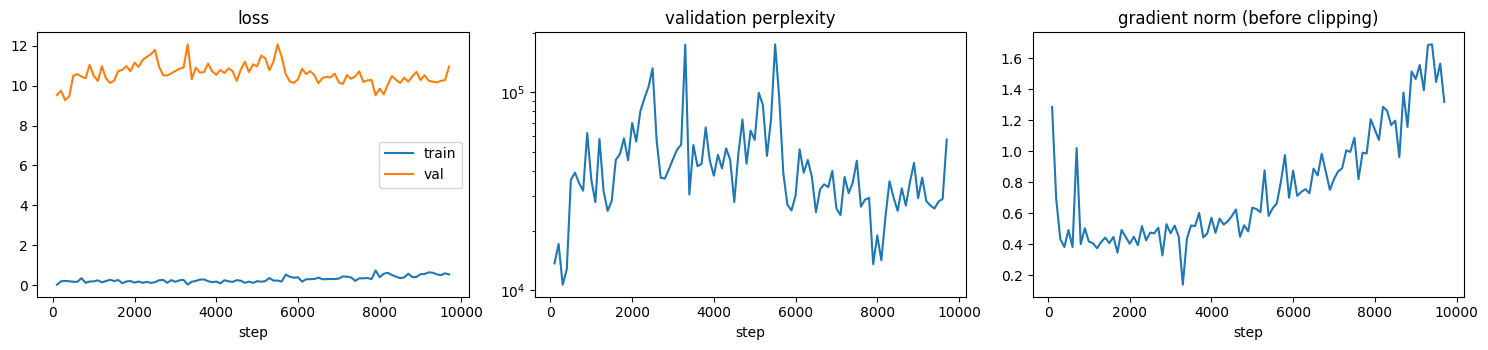

In [21]:
import matplotlib.pyplot as plt

steps = [h["step"] for h in history]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

ax[0].plot(steps, [h["train_loss"] for h in history], label="train")
ax[0].plot(steps, [h["val_loss"] for h in history], label="val")
ax[0].set(title="loss", xlabel="step")
ax[0].legend()

ax[1].plot(steps, [h["val_ppl"] for h in history])
ax[1].set(title="validation perplexity", xlabel="step", yscale="log")

ax[2].plot(steps, [h["grad_norm"] for h in history])
ax[2].set(title="gradient norm (before clipping)", xlabel="step")

plt.tight_layout()
plt.show()

In [22]:
from IPython.display import FileLink, display

display(FileLink(
    "checkpoints_fusion/fusion_final.pt",
    result_html_prefix="Download checkpoint: "
))

/kaggle/working/checkpoints_fusion/fusion_final.pt

## Generation and submission
Same decoding as the earlier runs (temperature + top-k + repetition penalty, EOS blocked so every continuation reaches 128 words). Since `model(idx)` returns logits for the whole window, the generator works unchanged for any causal model that follows the contract above.

In [ ]:
import json
from huggingface_hub import hf_hub_download, HfApi

REPO = "Exploration-Lab/CS-781-Capstone"
files = [f for f in HfApi().list_repo_files(REPO, repo_type="dataset") if "Phase_1" in f and "Test" in f]
print(files)                                   # check this is the Phase 1 test file
test_data = json.load(open(hf_hub_download(REPO, files[0], repo_type="dataset"), encoding="utf-8"))
print(len(test_data), "prompts")

In [ ]:
block = cfg.max_seq_len        # 1024


@torch.no_grad()
def generate_batch(model, x, block, eos_id, temperature=0.8, top_k=50, rep_penalty=1.1, max_new_tokens=400):
    model.eval()
    B, T0 = x.shape
    for i in range(max_new_tokens):
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(x[:, -block:])
        logits = (out[0] if isinstance(out, tuple) else out)[:, -1, :].float()
        logits[:, eos_id] = -float("inf")                  # we need a full 128 words
        window = x[:, -256:]
        s = logits.gather(1, window)
        s = torch.where(s > 0, s / rep_penalty, s * rep_penalty)
        logits.scatter_(1, window, s)
        logits = logits / temperature
        kth = torch.topk(logits, top_k)[0][:, -1:]
        logits[logits < kth] = -float("inf")
        nxt = torch.multinomial(F.softmax(logits, dim=-1), 1)
        x = torch.cat([x, nxt], dim=1)
        if (i + 1) % 16 == 0 and all(len(tokenizer.decode(r[T0:].tolist()).split()) > 128 for r in x):
            break
    return [tokenizer.decode(r[T0:].tolist()) for r in x]


def generate_texts(prompts, batch=8, prompt_tokens=800, **gen_kw):
    ids = [tokenizer.encode(p) for p in prompts]
    order = sorted(range(len(ids)), key=lambda i: len(ids[i]))
    outs = [None] * len(ids)
    for s in range(0, len(order), batch):
        idx = order[s:s + batch]
        L = min(prompt_tokens, block, min(len(ids[i]) for i in idx))
        x = torch.tensor([ids[i][-L:] for i in idx], device=device)
        for i, t in zip(idx, generate_batch(model, x, block, tokenizer.eos_id, **gen_kw)):
            outs[i] = " ".join(t.split()[:128])
    return outs

In [ ]:
from tqdm.auto import tqdm

SMOKE = True                 # True = 8 prompts only; set False for the full test set
PROMPT_TOKENS = 800
BATCH = 8
torch.manual_seed(42)

keys = list(test_data)[:8] if SMOKE else list(test_data)
ids = {k: tokenizer.encode(test_data[k]["text"]) for k in keys}
keys = sorted(keys, key=lambda k: len(ids[k]))          # similar lengths share a batch (no short prompt shrinks the others)

predictions = {}
for i in tqdm(range(0, len(keys), BATCH)):
    kb = keys[i:i + BATCH]
    L = min(PROMPT_TOKENS, block, min(len(ids[k]) for k in kb))
    x = torch.tensor([ids[k][-L:] for k in kb], device=device)
    for k, t in zip(kb, generate_batch(model, x, block, tokenizer.eos_id)):
        predictions[k] = {"text": " ".join(t.split()[:128])}

if SMOKE:
    for k in keys[:2]:
        print(predictions[k]["text"], "\n---")

In [ ]:
import zipfile

TAG = "fusion_T0.8_k50"          # change per run so you keep separate zips
assert not SMOKE, "set SMOKE = False and re-run the generation cell first"

# 1) repair any prediction that came out shorter than 128 words
for attempt in range(5):
    bad = [k for k, v in predictions.items() if len(v["text"].split()) != 128]
    if not bad:
        break
    print(f"attempt {attempt + 1}: regenerating {len(bad)} prediction(s)")
    torch.manual_seed(1000 + attempt)
    for k in bad:
        L = min(PROMPT_TOKENS, block, len(ids[k]))
        x = torch.tensor([ids[k][-L:]], device=device)
        words = generate_batch(model, x, block, tokenizer.eos_id, max_new_tokens=700)[0].split()
        if len(words) >= 128:
            predictions[k] = {"text": " ".join(words[:128])}
        elif len(words) > len(predictions[k]["text"].split()):
            predictions[k] = {"text": " ".join(words)}

still_bad = [k for k, v in predictions.items() if len(v["text"].split()) != 128]
for k in still_bad:                                          # last resort: repeat its own words
    words = predictions[k]["text"].split()
    if words:
        predictions[k] = {"text": " ".join((words * (128 // len(words) + 1))[:128])}
print(f"{len(still_bad)} prediction(s) needed the repeat-words fallback")

# 2) validate, write, zip
assert set(predictions) == set(test_data)
bad = [k for k, v in predictions.items() if len(v["text"].split()) != 128]
assert not bad, f"{len(bad)} predictions are not exactly 128 words, e.g. {bad[:3]}"

with open("prediction.json", "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False)
ZIP_NAME = f"submission_{TAG}.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    z.write("prediction.json", arcname="prediction.json")
print(zipfile.ZipFile(ZIP_NAME).namelist())                  # must print ['prediction.json']